# Práctica 2.2 · Regresión logística: ¿qué estudiantes están en riesgo de desertar?

Este cuaderno acompaña la clase «Regresión logística» y sigue su mismo recorrido:

1. Explorar los datos · 2. Separar **entrenamiento y validación** · 3. ¿Por qué no sirve una recta? · 4. **Regresión logística simple**: la curva S · 5. Cómo se estima: **máxima verosimilitud** · 6. Leer los coeficientes: **odds ratio** · 7. **Regresión logística múltiple** · 8. Del riesgo a la decisión: **umbral y matriz de confusión** · 9. **Métricas**: exactitud, precisión, sensibilidad, F1 y AUC contra una línea base · 10. Elegir el umbral con la **curva ROC** · 11. Hiperparámetros: regularización C y peso de las clases

**Datos.** `datos/2-2-regresion-logistica.xlsx` tiene 1.000 estudiantes de primer año **simulados con fines didácticos**: sede, zona de origen, sexo, edad, puntaje Saber 11, distancia de la vivienda a la sede, estrato, si trabaja, horas de trabajo, beca, si es primera generación en la universidad, promedio del primer semestre y si **desertó** al terminar el primer año (la variable objetivo). La deserción se generó con una ecuación logística conocida, así que se puede comprobar si el modelo recupera los efectos «verdaderos».

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, log_loss)
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, sube la carpeta datos/ al entorno
SEMILLA = 42
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

## 1. Cargar y explorar los datos

In [3]:
est = pd.read_excel(DATOS / '2-2-regresion-logistica.xlsx', sheet_name='estudiantes')
diccionario = pd.read_excel(DATOS / '2-2-regresion-logistica.xlsx', sheet_name='diccionario')
est['deserto'] = (est['desercion'] == 'Sí').astype(int)   # la Y como 0 y 1
print(est.shape)
est.head()

(1000, 15)


,id_estudiante,sede,zona_origen,sexo,edad,puntaje_saber11,distancia_km,estrato,trabaja,horas_trabajo,beca,primera_generacion,promedio_semestre,desercion,deserto
0,1,Duitama,Rural,Hombre,18,289,63.600,2,No,0,Sí,No,3.890,No,0
1,2,Duitama,Rural,Hombre,17,281,32.400,3,Sí,25,No,Sí,3.650,No,0
2,3,Tunja,Urbana,Mujer,17,319,20.000,3,No,0,Sí,No,3.910,No,0
3,4,Tunja,Rural,Hombre,19,202,52.400,1,Sí,39,No,Sí,3.440,No,0
4,5,Tunja,Rural,Hombre,18,297,20.800,3,No,0,Sí,Sí,3.660,No,0


In [4]:
diccionario

,variable,descripcion,tipo,unidad o valores
0,id_estudiante,Identificador del estudiante,Entero,—
1,sede,Sede donde estudia,Categórica nominal,4 sedes
2,zona_origen,Zona donde vivía antes de entrar,Categórica (binaria),Urbana / Rural
3,sexo,Sexo,Categórica (binaria),Hombre / Mujer
4,edad,Edad al ingresar,Numérica,años
5,puntaje_saber11,Puntaje global de la prueba Saber 11,Numérica,0–500
6,distancia_km,Distancia de la vivienda a la sede,Numérica,km
7,estrato,Estrato socioeconómico de la vivienda,Ordinal,1–5
8,trabaja,Trabaja mientras estudia,Categórica (binaria),Sí / No
9,horas_trabajo,Horas de trabajo por semana,Numérica,horas


In [5]:
print(f"Desertaron {est['deserto'].sum()} de {len(est)} estudiantes: {est['deserto'].mean():.1%}")
est.groupby('desercion')[['promedio_semestre', 'distancia_km', 'puntaje_saber11', 'horas_trabajo']].mean()

Desertaron 285 de 1000 estudiantes: 28.5%


,promedio_semestre,distancia_km,puntaje_saber11,horas_trabajo
desercion,,,,
No,3.380,17.321,266.144,7.122
Sí,2.933,27.579,246.621,10.295


Desertaron **285 de 1.000 estudiantes (28,5 %)**. Quien deserta llega con un **promedio más bajo** en el primer semestre (2,93 frente a 3,38), vive **más lejos** de la sede (27,6 km frente a 17,3 km), sacó un puntaje Saber 11 algo menor (247 frente a 266) y trabaja más horas a la semana (10,3 frente a 7,1).

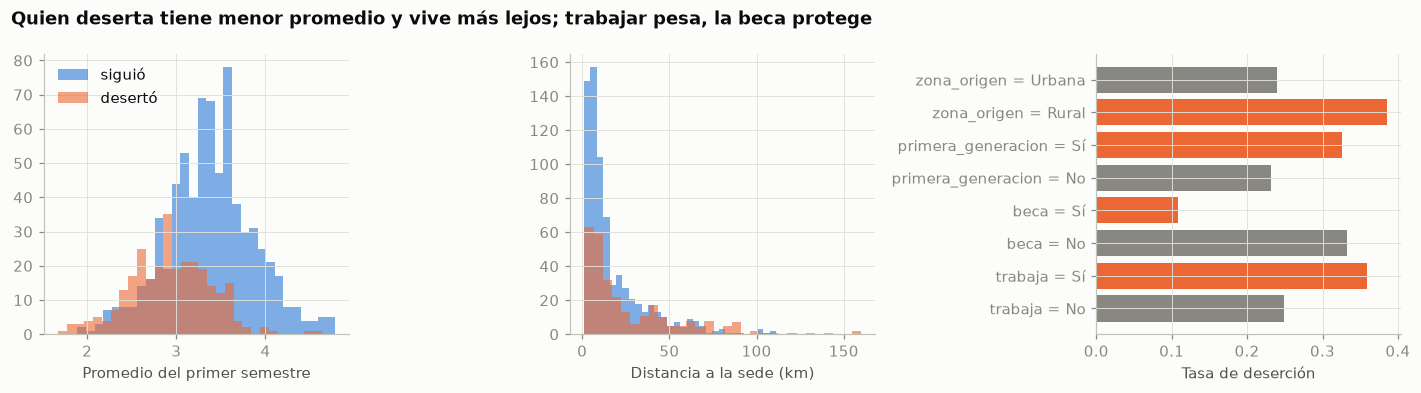

trabaja = No              0.249
trabaja = Sí              0.359
beca = No                 0.333
beca = Sí                 0.108
primera_generacion = No   0.232
primera_generacion = Sí   0.326
zona_origen = Rural       0.385
zona_origen = Urbana      0.240
Name: 0, dtype: float64

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, nombre in [(axs[0], 'promedio_semestre', 'Promedio del primer semestre'), (axs[1], 'distancia_km', 'Distancia a la sede (km)')]:
    for v, color, lab in [(0, AZUL, 'siguió'), (1, NARANJA, 'desertó')]:
        ax.hist(est.loc[est['deserto'] == v, col], bins=30, alpha=.6, color=color, label=lab)
    ax.set_xlabel(nombre)
axs[0].legend()
tasas = {c: est.groupby(c)['deserto'].mean() for c in ['trabaja', 'beca', 'primera_generacion', 'zona_origen']}
t = pd.DataFrame({f'{c} = {k}': [v[k]] for c, v in tasas.items() for k in v.index}).T[0]
axs[2].barh(t.index, t.values, color=[NARANJA if 'Sí' in i or 'Rural' in i else GRIS for i in t.index])
axs[2].set_xlabel('Tasa de deserción')
plt.suptitle('Quien deserta tiene menor promedio y vive más lejos; trabajar pesa, la beca protege', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()
t.round(3)

Las tasas por grupo cuentan la misma historia. Desertan el **35,9 % de quienes trabajan** frente al 24,9 % de quienes no; el **10,8 % de quienes tienen beca** frente al 33,3 % de quienes no; el 32,6 % de la primera generación frente al 23,2 %; y el **38,5 % de quienes vienen de zona rural** frente al 24,0 % de la urbana. Ojo: lo rural va muy de la mano con la distancia, así que el modelo múltiple tendrá que separar los dos efectos.

## 2. Separar entrenamiento y validación

En machine learning el modelo **aprende** con unos datos (entrenamiento) y se **evalúa** con otros que nunca vio (validación o prueba). Como solo el 29 % deserta, la partición se hace **estratificada**: los dos grupos conservan la misma proporción de desertores.

In [7]:
train, test = train_test_split(est, test_size=0.25, random_state=SEMILLA, stratify=est['deserto'])
print(f'Entrenamiento: {len(train)} estudiantes ({train["deserto"].mean():.1%} desertan)')
print(f'Prueba:        {len(test)} estudiantes ({test["deserto"].mean():.1%} desertan)')

Entrenamiento: 750 estudiantes (28.5% desertan)
Prueba:        250 estudiantes (28.4% desertan)


Quedan **750 estudiantes para entrenar y 250 para validar**. Gracias a la estratificación, los dos grupos tienen casi la misma tasa de deserción (28,5 % y 28,4 %).

## 3. ¿Por qué no sirve una recta?

La Y vale 0 o 1. Si se ajusta una regresión lineal (el «modelo lineal de probabilidad»), la recta no sabe que una probabilidad vive entre 0 y 1.

In [8]:
lpm = LinearRegression().fit(train[['promedio_semestre']], train['deserto'])
p_lin = lpm.predict(est[['promedio_semestre']])
print(f'Recta: deserción = {lpm.intercept_:.3f} + ({lpm.coef_[0]:.3f}) × promedio')
print(f'Predicciones por debajo de 0: {(p_lin < 0).sum()} · por encima de 1: {(p_lin > 1).sum()}')
print(f'Para un promedio de 4,8 la recta predice {lpm.predict(pd.DataFrame({"promedio_semestre": [4.8]}))[0]:.3f}: una «probabilidad» negativa')

Recta: deserción = 1.319 + (-0.317) × promedio
Predicciones por debajo de 0: 45 · por encima de 1: 0
Para un promedio de 4,8 la recta predice -0.203: una «probabilidad» negativa


La recta estimada es deserción = 1,319 − 0,317 × promedio. Para **45 estudiantes** predice un valor **por debajo de 0**, y para un promedio de 4,8 da **−0,203**: una «probabilidad» negativa, que no tiene sentido. Por eso, cuando la Y es 0 o 1, se necesita un modelo que respete los límites: la regresión logística.

## 4. Regresión logística simple: la curva S

La regresión logística no modela la Y directamente sino la **probabilidad** de que valga 1:

$$p = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x)}}$$

La parte de adentro, $z = \beta_0 + \beta_1 x$, es una recta como la de la regresión lineal; la función **sigmoide** la dobla en una curva S que siempre queda entre 0 y 1.

In [9]:
simple = smf.logit('deserto ~ promedio_semestre', data=train).fit(disp=0)
pd.DataFrame({'coeficiente': simple.params, 'error estándar': simple.bse, 'IC 2,5 %': simple.conf_int()[0],
              'IC 97,5 %': simple.conf_int()[1], 'p': simple.pvalues})

,coeficiente,error estándar,"IC 2,5 %","IC 97,5 %",p
Intercept,4.865,0.617,3.656,6.074,0.000
promedio_semestre,-1.825,0.197,-2.211,-1.439,0.000


El modelo estimado es $z = 4{,}865 - 1{,}825 \times \text{promedio}$, con $p = 1/(1+e^{-z})$. El coeficiente del promedio es **negativo**: a mejor promedio, menos riesgo de desertar. Su intervalo de 95 % (−2,211 a −1,439) no toca el cero (p < 0,001) e incluye el valor con el que se simularon los datos (−1,9). Igual que en la regresión lineal, el signo dice la dirección; la magnitud se lee distinto, como se verá en la sección 6.

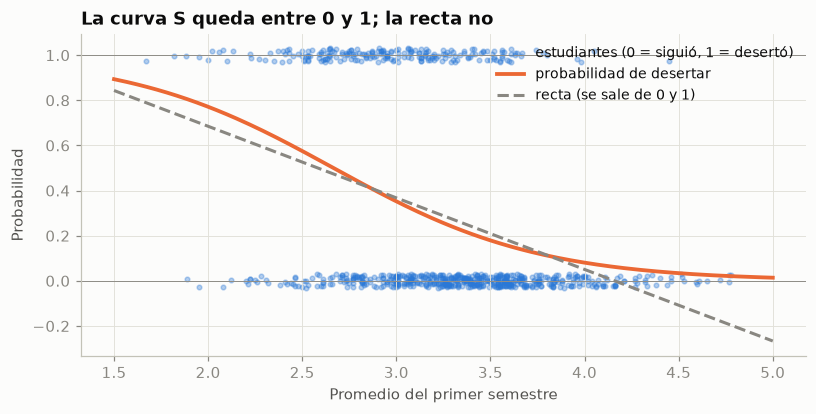

Promedio 2.5: probabilidad de desertar = 57.5%
Promedio 3.0: probabilidad de desertar = 35.2%
Promedio 3.5: probabilidad de desertar = 17.9%
Promedio 4.0: probabilidad de desertar = 8.1%


In [10]:
b0, b1 = simple.params
sig = lambda z: 1 / (1 + np.exp(-z))
fig, ax = plt.subplots(figsize=(8.5, 3.8))
jit = np.random.default_rng(SEMILLA).uniform(-.03, .03, len(train))
ax.scatter(train['promedio_semestre'], train['deserto'] + jit, s=9, alpha=.35, color=AZUL, label='estudiantes (0 = siguió, 1 = desertó)')
xx = np.linspace(1.5, 5, 200)
ax.plot(xx, sig(b0 + b1 * xx), color=NARANJA, lw=2.5, label='probabilidad de desertar')
ax.plot(xx, lpm.intercept_ + lpm.coef_[0] * xx, color=GRIS, ls='--', label='recta (se sale de 0 y 1)')
ax.axhline(0, color=GRIS, lw=.6); ax.axhline(1, color=GRIS, lw=.6)
ax.set_xlabel('Promedio del primer semestre'); ax.set_ylabel('Probabilidad'); ax.legend(loc='upper right', fontsize=9)
ax.set_title('La curva S queda entre 0 y 1; la recta no'); plt.show()
for x in [2.5, 3.0, 3.5, 4.0]:
    print(f'Promedio {x}: probabilidad de desertar = {sig(b0 + b1 * x):.1%}')

La curva S traduce el promedio en probabilidad: con **2,5 el riesgo de desertar es 57,5 %**, con 3,0 baja a 35,2 %, con 3,5 a 17,9 % y con **4,0 a solo 8,1 %**. La recta gris, en cambio, cruza por debajo de 0 para los promedios altos.

## 5. Cómo se estima: máxima verosimilitud

Aquí no hay mínimos cuadrados. El algoritmo busca los $\beta$ que hacen **más probable** lo que de verdad pasó: para quien desertó quiere un $p$ alto, y para quien siguió, un $p$ bajo. Eso se resume en la **log-verosimilitud**:

$$\ell(\beta) = \sum \left[ y \log p + (1-y) \log (1-p) \right]$$

No hay una fórmula cerrada como en la regresión lineal: el computador **sube por la colina** paso a paso hasta el máximo. La pérdida que minimiza `scikit-learn` (*log loss*) es la misma cantidad con el signo cambiado y dividida por n.

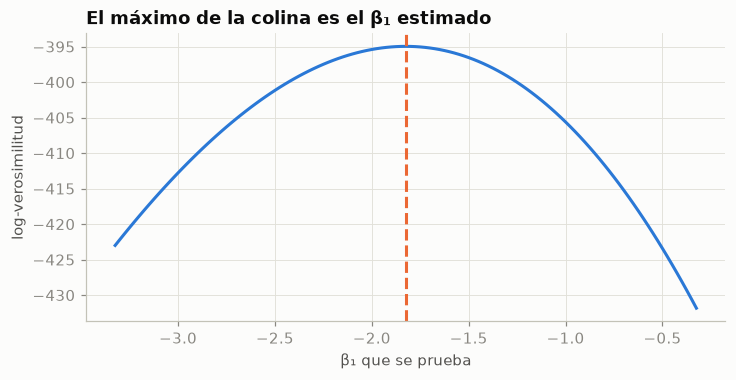

Máximo de la curva en β₁ ≈ -1.825; statsmodels estimó -1.825
Log-verosimilitud en el máximo: -395.0 · log loss = 0.5266


In [11]:
y, x = train['deserto'].values, train['promedio_semestre'].values
def loglik(b0, b1):
    p = sig(b0 + b1 * x); return np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))
grid = np.linspace(b1 - 1.5, b1 + 1.5, 121)
ll = [loglik(b0 - (g - b1) * x.mean(), g) for g in grid]   # se mueve β1 y β0 lo acompaña por el punto medio
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(grid, ll, color=AZUL); ax.axvline(b1, color=NARANJA, ls='--')
ax.set_xlabel('β₁ que se prueba'); ax.set_ylabel('log-verosimilitud'); ax.set_title('El máximo de la colina es el β₁ estimado'); plt.show()
print(f'Máximo de la curva en β₁ ≈ {grid[np.argmax(ll)]:.3f}; statsmodels estimó {b1:.3f}')
print(f'Log-verosimilitud en el máximo: {simple.llf:.1f} · log loss = {-simple.llf / len(train):.4f}')

La curva de log-verosimilitud tiene **un solo máximo**, justo en **β₁ = −1,825**: el mismo valor que entregó `statsmodels`. Esa es la «colina» que sube el algoritmo. En el máximo, la log-verosimilitud vale −395,0, que equivale a un **log loss de 0,5266** por estudiante: la cantidad que minimiza `scikit-learn`.

## 6. Leer los coeficientes: odds y odds ratio

- La **probabilidad** $p$ va de 0 a 1. Las **odds** (chances) son $p/(1-p)$: una probabilidad de 0,20 son odds de 0,25, «1 a 4».
- El modelo es lineal en el **logaritmo de las odds**: $\log\frac{p}{1-p} = \beta_0 + \beta_1 x$.
- Por eso $e^{\beta_1}$, el **odds ratio**, dice **por cuánto se multiplican las odds** cuando x sube una unidad. Si es menor que 1 las reduce; si es mayor que 1 las aumenta.

In [12]:
or1 = np.exp(b1)
print(f'Odds ratio del promedio: e^({b1:.3f}) = {or1:.3f}')
print(f'Un punto más de promedio multiplica las odds de desertar por {or1:.3f}: las reduce en {1 - or1:.1%}')
print(f'Medio punto más: e^({b1:.3f} × 0,5) = {np.exp(b1 * .5):.3f}')
for a, b in [(2.5, 3.5), (3.0, 4.0)]:
    pa, pb = sig(b0 + b1 * a), sig(b0 + b1 * b)
    print(f'De {a} a {b}: la probabilidad pasa de {pa:.1%} a {pb:.1%} (odds de {pa/(1-pa):.3f} a {pb/(1-pb):.3f}, razón {pb/(1-pb)/(pa/(1-pa)):.3f})')

Odds ratio del promedio: e^(-1.825) = 0.161
Un punto más de promedio multiplica las odds de desertar por 0.161: las reduce en 83.9%
Medio punto más: e^(-1.825 × 0,5) = 0.402
De 2.5 a 3.5: la probabilidad pasa de 57.5% a 17.9% (odds de 1.354 a 0.218, razón 0.161)
De 3.0 a 4.0: la probabilidad pasa de 35.2% a 8.1% (odds de 0.544 a 0.088, razón 0.161)


El **odds ratio del promedio es 0,161**: cada punto más de promedio multiplica las odds de desertar por 0,161, es decir, **las reduce en un 83,9 %**. Medio punto más las multiplica por 0,402. La lección clave está en las dos últimas líneas. Subir de 2,5 a 3,5 baja la probabilidad **39,6 puntos** (de 57,5 % a 17,9 %), y subir de 3,0 a 4,0 la baja solo 27,1 puntos (de 35,2 % a 8,1 %). En cambio, **la razón de odds es la misma (0,161) en los dos casos**. En la regresión logística el efecto es constante sobre las odds, no sobre la probabilidad.

## 7. Regresión logística múltiple

$\log\frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$. Cada odds ratio se lee **con las demás variables constantes**. Las variables de texto entran como ficticias contra su categoría de referencia (no trabaja, sin beca, no es primera generación, zona urbana).

In [13]:
formula = ('deserto ~ promedio_semestre + distancia_km + C(trabaja) + C(beca) + C(primera_generacion)'
           ' + puntaje_saber11 + C(zona_origen, Treatment("Urbana")) + C(sexo) + estrato')
multiple = smf.logit(formula, data=train).fit(disp=0)
nombres = {'promedio_semestre': '+1 punto de promedio', 'distancia_km': '+1 km de distancia', 'C(trabaja)[T.Sí]': 'Trabaja (vs. no)',
           'C(beca)[T.Sí]': 'Tiene beca (vs. no)', 'C(primera_generacion)[T.Sí]': 'Primera generación (vs. no)',
           'puntaje_saber11': '+1 punto Saber 11', 'C(zona_origen, Treatment("Urbana"))[T.Rural]': 'Origen rural (vs. urbano)',
           'C(sexo)[T.Mujer]': 'Mujer (vs. hombre)', 'estrato': '+1 estrato'}
tabla = pd.DataFrame({'coeficiente': multiple.params, 'odds ratio': np.exp(multiple.params),
                      'OR IC 2,5 %': np.exp(multiple.conf_int()[0]), 'OR IC 97,5 %': np.exp(multiple.conf_int()[1]),
                      'p': multiple.pvalues}).drop(index='Intercept').rename(index=nombres)
tabla

,coeficiente,odds ratio,"OR IC 2,5 %","OR IC 97,5 %",p
Trabaja (vs. no),0.273,1.314,0.902,1.913,0.154
Tiene beca (vs. no),-0.974,0.378,0.216,0.660,0.001
Primera generación (vs. no),0.335,1.398,0.963,2.030,0.078
Origen rural (vs. urbano),0.220,1.246,0.704,2.205,0.450
Mujer (vs. hombre),-0.232,0.793,0.555,1.132,0.201
+1 punto de promedio,-1.740,0.175,0.113,0.273,0.000
+1 km de distancia,0.016,1.016,1.005,1.028,0.006
+1 punto Saber 11,-0.001,0.999,0.993,1.006,0.855
+1 estrato,0.094,1.099,0.835,1.445,0.501


Con todas las variables, cada odds ratio se lee **con lo demás constante**:

- **Promedio:** 0,175 por punto (IC 0,113 a 0,273). Es el factor más fuerte.
- **Beca:** 0,378. Tener beca reduce las odds de desertar un 62 % (p = 0,001).
- **Distancia:** 1,016 por km (p = 0,006). Parece poco, pero 10 km más multiplican las odds por 1,016¹⁰ ≈ 1,17.
- **Trabaja** (1,314) y **primera generación** (1,398) van en la dirección esperada, pero sus intervalos tocan el 1 (p = 0,154 y 0,078). Con 750 estudiantes no alcanza la evidencia para afirmarlos.
- **Origen rural:** 1,246, con p = 0,450. Al controlar la distancia, lo rural ya no agrega nada. En la simulación la zona no tenía efecto propio: su efecto aparente en la sección 1 era la distancia.

Los valores con que se simularon los datos (promedio 0,150, beca 0,47, distancia 1,016, trabaja 1,73, primera generación 1,42) caen todos dentro de sus intervalos.

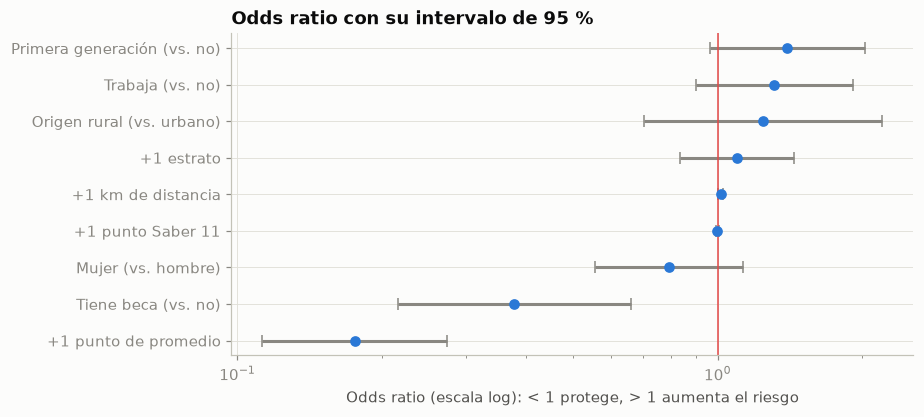

In [14]:
t = tabla.sort_values('odds ratio')
fig, ax = plt.subplots(figsize=(8, 3.8))
yv = np.arange(len(t))
ax.errorbar(t['odds ratio'], yv, xerr=[t['odds ratio'] - t['OR IC 2,5 %'], t['OR IC 97,5 %'] - t['odds ratio']],
            fmt='o', color=AZUL, ecolor=GRIS, capsize=4)
ax.axvline(1, color=ROJO, lw=1); ax.set_xscale('log'); ax.set_yticks(yv, t.index)
ax.set_xlabel('Odds ratio (escala log): < 1 protege, > 1 aumenta el riesgo'); ax.set_title('Odds ratio con su intervalo de 95 %')
plt.show()

El gráfico resume la tabla: a la izquierda del 1 están los factores que **protegen** (promedio, beca) y a la derecha los que **aumentan el riesgo** (distancia, trabajar, primera generación). Solo tres intervalos no cruzan la línea roja: **promedio, beca y distancia**. Son los efectos que estos datos permiten afirmar con un 95 % de confianza.

## 8. Del riesgo a la decisión: umbral y matriz de confusión

El modelo entrega una **probabilidad**. Para decidir (por ejemplo, a quién llama la oficina de bienestar) hay que fijar un **umbral**: si $p \ge$ umbral se predice «desertará». Con 0,5 por defecto, la **matriz de confusión** cruza lo real con lo predicho:

| | Predijo: sigue | Predijo: deserta |
|---|---|---|
| **Real: siguió** | VN · verdadero negativo | FP · falso positivo (falsa alarma) |
| **Real: desertó** | FN · falso negativo (el que se escapa) | VP · verdadero positivo |

In [15]:
p_te = multiple.predict(test)
pred = (p_te >= 0.5).astype(int)
mc = pd.DataFrame(confusion_matrix(test['deserto'], pred), index=['Real: siguió', 'Real: desertó'], columns=['Predijo: sigue', 'Predijo: deserta'])
mc

,Predijo: sigue,Predijo: deserta
Real: siguió,164,15
Real: desertó,42,29


Con el umbral de 0,5, de los **71 estudiantes de prueba que desertaron**, el modelo identifica a **29 (VP)** y **se le escapan 42 (FN)**. De los 179 que siguieron, señala por error a 15 (FP, falsas alarmas). Para una oficina de bienestar, esos 42 que se escapan son el problema principal.

## 9. Métricas de desempeño

Todas salen de la matriz de confusión, y se calculan en **prueba**:

| Métrica | Nombre en inglés | Fórmula | Responde |
|---|---|---|---|
| Exactitud | *accuracy* | (VP + VN) / total | ¿Qué parte acierta? |
| Precisión | *precision* | VP / (VP + FP) | De los que señala, ¿cuántos sí desertan? |
| Sensibilidad | *recall* | VP / (VP + FN) | De los que desertan, ¿a cuántos encuentra? |
| F1 | *F1 score* | 2·P·S / (P + S) | Balance entre precisión y sensibilidad |
| AUC | *Area Under the ROC Curve* | área bajo la curva ROC | ¿Ordena bien el riesgo, sin importar el umbral? |

La **línea base** es predecir para todos la clase mayoritaria («nadie deserta»).

In [16]:
def metricas(y, p, umbral=0.5):
    yhat = (p >= umbral).astype(int)
    return {'exactitud': accuracy_score(y, yhat), 'precisión': precision_score(y, yhat, zero_division=0),
            'sensibilidad': recall_score(y, yhat), 'F1': f1_score(y, yhat), 'AUC': roc_auc_score(y, p) if np.std(p) > 0 else 0.5}
yte, ytr = test['deserto'], train['deserto']
res = pd.DataFrame({
    'Línea base (nadie deserta)': metricas(yte, np.zeros(len(test))),
    'Simple (promedio)': metricas(yte, simple.predict(test)),
    'Múltiple': metricas(yte, p_te),
}).T
res

,exactitud,precisión,sensibilidad,F1,AUC
Línea base (nadie deserta),0.716,0.000,0.000,0.000,0.500
Simple (promedio),0.780,0.711,0.380,0.495,0.803
Múltiple,0.772,0.659,0.408,0.504,0.827


La **línea base** muestra la **trampa de la exactitud**. Diciendo «nadie deserta» acierta el **71,6 %**, pero su sensibilidad es **0**: no encuentra a ningún desertor. Por eso, con clases desbalanceadas, la exactitud sola engaña.

- **Modelo simple:** exactitud 0,780, sensibilidad 0,380, AUC 0,803.
- **Modelo múltiple:** exactitud apenas menor (0,772), pero **mejor sensibilidad (0,408), F1 (0,504) y AUC (0,827)**.

El AUC dice que, si se toma al azar un desertor y alguien que siguió, el modelo múltiple le da más riesgo al desertor el 82,7 % de las veces.

In [17]:
comp = pd.DataFrame({'entrenamiento': metricas(ytr, multiple.predict(train)), 'prueba': metricas(yte, p_te)}).T
comp

,exactitud,precisión,sensibilidad,F1,AUC
entrenamiento,0.767,0.654,0.388,0.487,0.771
prueba,0.772,0.659,0.408,0.504,0.827


Entrenamiento y prueba dan cifras parecidas: el AUC es 0,771 en entrenamiento y 0,827 en prueba, y el F1 es 0,487 y 0,504. El modelo **no está sobreajustado**: no memorizó los datos con que aprendió. Que la prueba salga un poco mejor es azar de la muestra de 250 estudiantes.

## 10. Elegir el umbral con la curva ROC

La curva **ROC** (*Receiver Operating Characteristic*) recorre todos los umbrales posibles y grafica la **sensibilidad** (desertores encontrados) contra la **tasa de falsas alarmas** (1 − especificidad). Un modelo al azar queda en la diagonal (AUC = 0,5); uno perfecto llega a la esquina superior izquierda (AUC = 1).

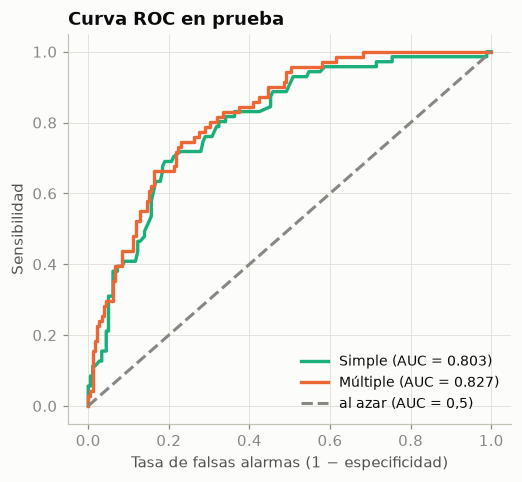

,exactitud,precisión,sensibilidad,F1
umbral,,,,
0.200,0.632,0.430,0.901,0.582
0.300,0.736,0.524,0.775,0.625
0.400,0.776,0.612,0.577,0.594
0.500,0.772,0.659,0.408,0.504
0.600,0.764,0.700,0.296,0.416


In [18]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for nombre, p, color in [('Simple', simple.predict(test), AQUA), ('Múltiple', p_te, NARANJA)]:
    fpr, tpr, _ = roc_curve(yte, p)
    ax.plot(fpr, tpr, color=color, lw=2.2, label=f'{nombre} (AUC = {roc_auc_score(yte, p):.3f})')
ax.plot([0, 1], [0, 1], color=GRIS, ls='--', label='al azar (AUC = 0,5)')
ax.set_xlabel('Tasa de falsas alarmas (1 − especificidad)'); ax.set_ylabel('Sensibilidad'); ax.legend(loc='lower right', fontsize=9)
ax.set_title('Curva ROC en prueba'); plt.show()
umbrales = pd.DataFrame({u: metricas(yte, p_te, u) for u in [0.2, 0.3, 0.4, 0.5, 0.6]}).T.drop(columns='AUC')
umbrales.index.name = 'umbral'
umbrales

La curva ROC del modelo múltiple queda por encima de la del simple, y las dos muy lejos de la diagonal del azar. La tabla de umbrales muestra la decisión real:

- Con el umbral de **0,5** se encuentra solo al **40,8 %** de los desertores.
- Bajándolo a **0,3**, la sensibilidad sube a **77,5 %** y la precisión baja a 52,4 %: de cada dos alertas, una es un desertor real. Además, el **F1 es el mejor (0,625)**.
- Con **0,2** se encuentra al 90,1 %, a costa de muchas más falsas alarmas (precisión 43,0 %).

Como una llamada de bienestar cuesta poco y perder a un estudiante cuesta mucho, aquí conviene un umbral bajo. **El umbral es una decisión del investigador, no del algoritmo.**

## 11. ¿Y los hiperparámetros?

La regresión logística de `scikit-learn` trae **regularización** por defecto. Su hiperparámetro es **C**, el inverso de λ: un C pequeño castiga más los coeficientes (los encoge); un C grande casi no los castiga. El otro ajuste útil es `class_weight='balanced'`, que da más peso a la clase minoritaria (los desertores). Los dos se eligen con **validación cruzada** en entrenamiento, nunca con la prueba.

In [19]:
num = ['promedio_semestre', 'distancia_km', 'puntaje_saber11', 'estrato']
def matriz(d):
    X = d[num].copy()
    for c in ['trabaja', 'beca', 'primera_generacion']: X[c] = (d[c] == 'Sí').astype(int)
    X['rural'] = (d['zona_origen'] == 'Rural').astype(int); X['mujer'] = (d['sexo'] == 'Mujer').astype(int)
    return X
Xtr, Xte = matriz(train), matriz(test)
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
busqueda = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                        {'logisticregression__C': np.logspace(-3, 2, 11), 'logisticregression__class_weight': [None, 'balanced']},
                        cv=cv, scoring='roc_auc').fit(Xtr, ytr)
print('Mejor combinación:', busqueda.best_params_, f'· AUC en validación cruzada = {busqueda.best_score_:.3f}')
filas = {}
for cw in [None, 'balanced']:
    m = make_pipeline(StandardScaler(), LogisticRegression(C=busqueda.best_params_['logisticregression__C'], class_weight=cw, max_iter=2000)).fit(Xtr, ytr)
    filas[f'class_weight = {cw}'] = metricas(yte, m.predict_proba(Xte)[:, 1])
pd.DataFrame(filas).T

Mejor combinación: {'logisticregression__C': np.float64(0.1), 'logisticregression__class_weight': None} · AUC en validación cruzada = 0.754


,exactitud,precisión,sensibilidad,F1,AUC
class_weight = None,0.772,0.684,0.366,0.477,0.825
class_weight = balanced,0.716,0.500,0.789,0.612,0.828


La validación cruzada eligió **C = 0,1** (regularización moderada) y no balancear las clases, con un AUC de validación cruzada de 0,754.

- **AUC en prueba:** casi no cambia con el balanceo (0,825 frente a 0,828), porque el AUC no depende del umbral.
- **Con `class_weight='balanced'`:** la **sensibilidad sube de 0,366 a 0,789** y el F1 de 0,477 a 0,612, y la precisión baja a 0,500.

Balancear las clases tiene un efecto muy parecido a bajar el umbral. Son dos caminos para la misma decisión: cuánto pesa no encontrar a un desertor.

## Conclusiones

| Pregunta | Respuesta con estos datos |
|---|---|
| ¿Por qué no una recta? | Predice «probabilidades» negativas (45 estudiantes por debajo de 0) |
| ¿Qué modela la logística? | La probabilidad, con una curva S: $p = 1/(1+e^{-z})$, donde $z = \beta_0 + \beta_1 x$ |
| ¿Cómo se estima? | Por máxima verosimilitud: el β que hace más probable lo observado (β₁ = −1,825) |
| ¿Cómo se lee β? | Con el odds ratio $e^\beta$: cada punto de promedio multiplica las odds de desertar por 0,161 |
| ¿Qué importa con lo demás constante? | Promedio (OR 0,175), beca (0,378) y distancia (1,016 por km); lo rural deja de importar al controlar la distancia |
| ¿Cómo se evalúa? | En prueba, con la matriz de confusión: exactitud, precisión, sensibilidad, F1 y AUC (0,827), siempre contra la línea base |
| ¿Qué enseña la línea base? | Acierta el 71,6 % sin encontrar a un solo desertor: la exactitud engaña con clases desbalanceadas |
| ¿Qué umbral usar? | Depende del costo de cada error: con 0,3 se encuentra al 77,5 % de los desertores |
| ¿Hiperparámetros? | C (regularización) y `class_weight`; se eligen con validación cruzada |

La regresión logística es a la vez un modelo para **explicar** (odds ratio con intervalo) y para **clasificar** (probabilidad, umbral y métricas en prueba). En una investigación conviene reportar las dos caras y justificar el umbral elegido.

## Retos

1. **Otra X en la simple.** Ajuste la logística simple con `distancia_km` en lugar del promedio. ¿Cuánto vale el odds ratio de 10 km? ¿Y el AUC?
2. **Horas en lugar de «trabaja».** Reemplace `C(trabaja)` por `horas_trabajo`. ¿Cuál de las dos versiones explica mejor el riesgo?
3. **Interacción.** Agregue `C(beca):distancia_km`. ¿La beca protege más a quien vive lejos?
4. **Métricas por grupo.** Calcule la sensibilidad por separado para estudiantes rurales y urbanos con el umbral 0,3. ¿A quién se le escapan más desertores? ¿Qué implicaría eso para un programa de bienestar?
5. **El umbral óptimo.** Suponga que no encontrar a un desertor cuesta 5 veces más que una falsa alarma. Calcule el costo total para umbrales de 0,1 a 0,6 y elija el mejor.